# Performance of Major Bank Stocks

## Introduction

This project analyses the stock performance of major global banks from 2018 to 2023, covering three Singapore banks (DBS, OCBC, UOB) and four global banks (Bank of America, 
HSBC, Goldman Sachs, JP Morgan). Using daily closing prices sourced from yfinance, the  analysis examines how these stocks performed relative to one another and how they responded to key macroeconomic events, specifically the COVID 19 pandemic and the 2022 Federal Reserve interest rate hike cycle. The analysis further applies Monte Carlo simulation and mathematical optimisation to identify the optimal portfolio allocation across these seven banks.

In [146]:
pip install yfinance

433441.16s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [147]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Data cleaning

In [148]:
# DBS, OCBC, UOB, JP Morgan, Goldman Sachs, Bank of America, HSBC
tickers = ["D05.SI", "O39.SI", "U11.SI", "JPM", "GS", "BAC", "HSBA.L"]

data = yf.download(tickers, start="2018-01-01", end="2024-01-01")
data.dropna(inplace=True)

data.head()

[*********************100%***********************]  7 of 7 completed


Price           Close                                                          \
Ticker            BAC     D05.SI          GS      HSBA.L        JPM    O39.SI   
Date                                                                            
2018-01-02  24.385727  14.367955  211.174728  761.671936  85.091499  8.141765   
2018-01-03  24.304173  14.755660  209.208969  759.979675  85.178207  8.278654   
2018-01-04  24.622250  15.109160  212.132889  762.667480  86.398438  8.441621   
2018-01-05  24.736423  15.006531  211.050827  760.079163  85.843788  8.441621   
2018-01-08  24.565159  15.080650  207.986481  754.603882  85.970581  8.467695   

Price                       High                         ...       Open  \
Ticker         U11.SI        BAC     D05.SI          GS  ...        JPM   
Date                                                     ...              
2018-01-02  17.194118  24.385727  14.367955  213.024897  ...  84.839260   
2018-01-03  17.368450  24.418354  14.767064  211.562990  ...  85.020560   
2018-01-04  17.445930  24.826144  15.109160  214.519943  ...  85.859636   
2018-01-05  17.374901  24.809825  15.154771  212.677968  ...  86.572760   
2018-01-08  17.594431  24.687495  15.086352  210.769982  ...  85.693258   

Price                                Volume                                    \
Ticker        O39.SI     U11.SI         BAC     D05.SI         GS      HSBA.L   
Date                                                                            
2018-01-02  8.083097  17.045615  57121600.0  3155680.0  2258300.0  14948356.0   
2018-01-03  8.148282  17.207033  57865700.0  5108070.0  2988200.0  17643845.0   
2018-01-04  8.298211  17.394277  76512500.0  6269670.0  2583200.0  21951829.0   
2018-01-05  8.441621  17.433011  56445200.0  4527820.0  2594700.0  19200215.0   
2018-01-08  8.474214  17.426557  42914800.0  2881450.0  2940500.0  22109518.0   

Price                                         
Ticker             JPM     O39.SI     U11.SI  
Date                                          
2018-01-02  13578800.0  2015000.0  1695800.0  
2018-01-03  11901000.0  5015200.0  2270800.0  
2018-01-04  12953700.0  6524000.0  3076700.0  
2018-01-05  14155000.0  3426200.0  1811200.0  
2018-01-08  12466500.0  3589700.0  1775400.0  

[5 rows x 35 columns]

In [149]:
# subset only closing price 

data = data[['Close']]
data.columns = data.columns.get_level_values(1)
data.head()

Ticker,BAC,D05.SI,GS,HSBA.L,JPM,O39.SI,U11.SI
Date,,,,,,,
2018-01-02,24.385727,14.367955,211.174728,761.671936,85.091499,8.141765,17.194118
2018-01-03,24.304173,14.755660,209.208969,759.979675,85.178207,8.278654,17.368450
2018-01-04,24.622250,15.109160,212.132889,762.667480,86.398438,8.441621,17.445930
2018-01-05,24.736423,15.006531,211.050827,760.079163,85.843788,8.441621,17.374901
2018-01-08,24.565159,15.080650,207.986481,754.603882,85.970581,8.467695,17.594431


Qns: 
- how do prices fluctuate for each bank? (daily return/cummulative return - return on investments)
- do the stock prices move together (ie. are they correlated?)
- how much risk is there in holding a stock (standard deviation/ volatility - how much they fluctuate)
- so what? which stock should i invest in?

### Daily returns

In [150]:
daily_returns = data.pct_change().dropna()
daily_returns.head()

Ticker,BAC,D05.SI,GS,HSBA.L,JPM,O39.SI,U11.SI
Date,,,,,,,
2018-01-03,-0.003344,0.026984,-0.009309,-0.002222,0.001019,0.016813,0.010139
2018-01-04,0.013087,0.023957,0.013976,0.003537,0.014326,0.019685,0.004461
2018-01-05,0.004637,-0.006793,-0.005101,-0.003394,-0.006420,0.000000,-0.004071
2018-01-08,-0.006924,0.004939,-0.014519,-0.007204,0.001477,0.003089,0.012635
2018-01-09,0.004980,0.002269,0.008459,0.010950,0.005069,-0.006159,0.020184


### Cummulative returns 
if i invested $1 at the start of 2018, how much would i have at the particular date (how much have i earned/lost)

In [151]:
cumulative_returns = (1 + daily_returns).cumprod()
cumulative_returns.head()

Ticker,BAC,D05.SI,GS,HSBA.L,JPM,O39.SI,U11.SI
Date,,,,,,,
2018-01-03,0.996656,1.026984,0.990691,0.997778,1.001019,1.016813,1.010139
2018-01-04,1.009699,1.051587,1.004537,1.001307,1.015359,1.036829,1.014645
2018-01-05,1.014381,1.044444,0.999413,0.997909,1.008841,1.036829,1.010514
2018-01-08,1.007358,1.049603,0.984902,0.990720,1.010331,1.040032,1.023282
2018-01-09,1.012375,1.051984,0.993234,1.001569,1.015453,1.033627,1.043935


### Volatility
short term volatility, how much does the stock price fluctuate over a period of time - how volatile/risky is it

In [152]:
volatility = daily_returns.rolling(window=30).std().dropna()
volatility.head()

Ticker,BAC,D05.SI,GS,HSBA.L,JPM,O39.SI,U11.SI
Date,,,,,,,
2018-02-14,0.017923,0.015249,0.020017,0.011891,0.016675,0.012512,0.011891
2018-02-15,0.017904,0.014641,0.020189,0.011903,0.016676,0.014459,0.013039
2018-02-20,0.017912,0.014244,0.020183,0.012417,0.016609,0.014010,0.013070
2018-02-21,0.017919,0.014822,0.020189,0.012713,0.016540,0.014224,0.013274
2018-02-22,0.017899,0.015226,0.020040,0.013456,0.016556,0.014281,0.013103


## Plots

## 1. Which bank performed best overall (highest return)

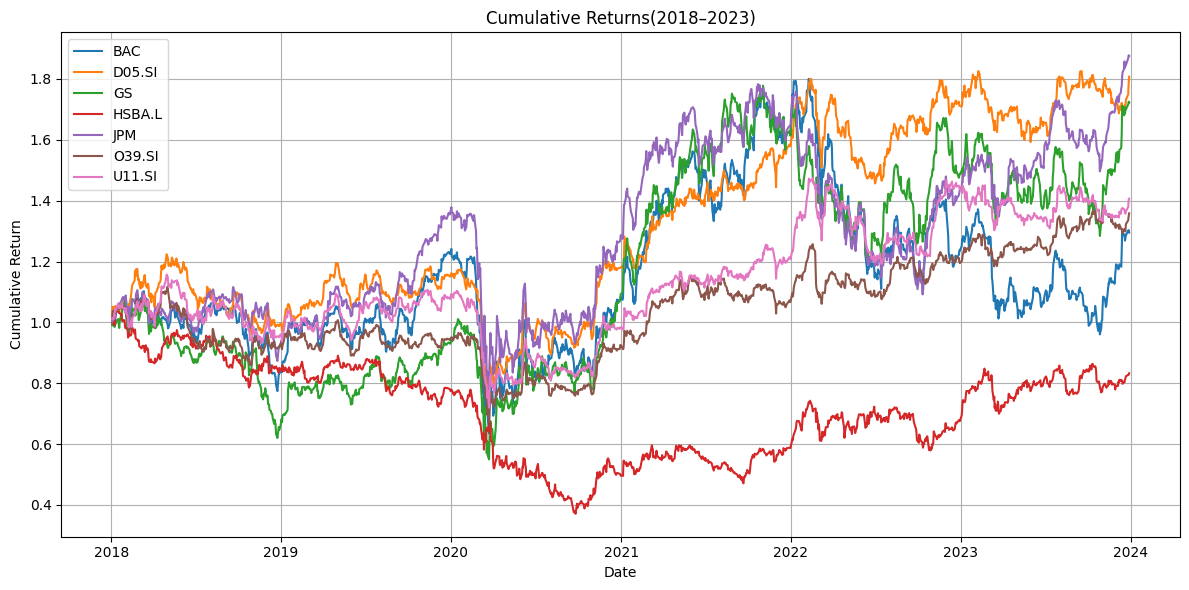

In [153]:
plt.figure(figsize=(12, 6))
for col in cumulative_returns.columns:
    plt.plot(cumulative_returns.index, cumulative_returns[col], label=col)

plt.title("Cumulative Returns(2018–2023)")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

JP Morgan and DBS are constantly among the top few performers throughout the 6 years. 
One similartity we can observe is that there was a huge dip in stock prices during the COVID 19 pandemic. This could be due to widespread economic shutdown and uncertainty in future corporate earnings, causing investor confidence to plummet, and thus prices. There was also a slight dip in prices around mid 2022 likely due to the fed rate hike cycle, where the US federal reserve increased interest rates, in turn cost of borrowing and lower profits. It can be inferred that when a major macro event occurs, stock prices and returns can fluctuate either up if outlook is great or down if economic outlook is pessimistic. 

## 2. Which stock was the riskiest to hold? 

In [154]:
avg_volatility = volatility.mean() * (252 ** 0.5)  # annualised, 252 trading days/year
avg_volatility.head()

Ticker
BAC       0.314107
D05.SI    0.186151
GS        0.294506
HSBA.L    0.256545
JPM       0.273895
dtype: float64

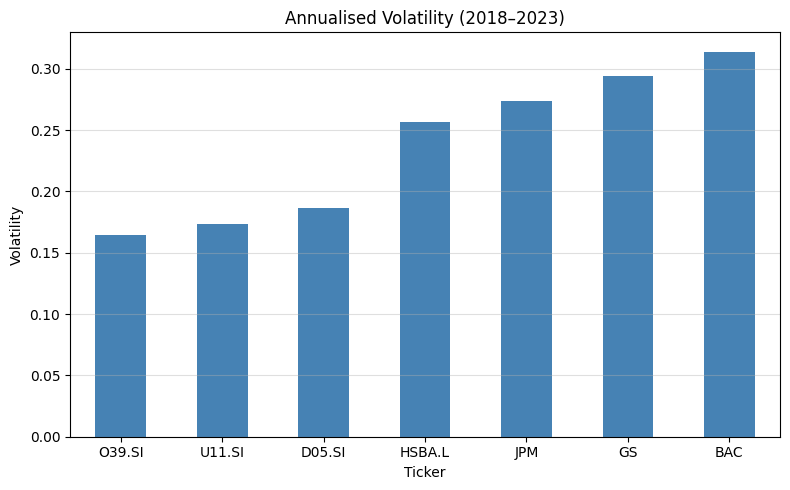

In [155]:
plt.figure(figsize=(8, 5))
avg_volatility.sort_values().plot(kind='bar', color='steelblue')
plt.title("Annualised Volatility (2018–2023)")
plt.ylabel("Volatility")
plt.xticks(rotation=0)
plt.grid(axis='y',alpha=0.4)
plt.tight_layout()
plt.show()

Across the 6 years, OCBC had the lowest volatility. In fact, the Singapore banks had lowest volatility, while Bank of America faced highest volatility, meaning prices and thus returns fluctuated the most. This could be because Singapore banks operate as conservative, dividend focused commercial lenders (ie. generate revnue from stable and commercial loans, wealth management fees etc, all of which generate predictable and steady income) while US and global banks act as highly cyclical investment vehicles that are exposed to capital markets (eg. JPM  and GS generate revenue from investment banking, asset management etc, all of which are very sensitive to market crashes and shifts in coperate sentiment).

### 2b. Do different time periods affect volatility? 

In [156]:

# volatility for each period
pre_covid = volatility["2018":"2019"].mean() * (252 ** 0.5)
covid = volatility["2020":"2021"].mean() * (252 ** 0.5)
post_covid = volatility["2022":"2024"].mean() * (252 ** 0.5)

print("Pre-COVID (2018-2019)")
print(pre_covid)
print("\nCOVID (2020-2021)")
print(covid)
print("\nPost-COVID (2022-2024)")
print(post_covid)


Pre-COVID (2018-2019)
Ticker
BAC       0.242068
D05.SI    0.175692
GS        0.244633
HSBA.L    0.179338
JPM       0.206116
O39.SI    0.167492
U11.SI    0.172702
dtype: float64

COVID (2020-2021)
Ticker
BAC       0.390013
D05.SI    0.217804
GS        0.357788
HSBA.L    0.325690
JPM       0.352383
O39.SI    0.190228
U11.SI    0.187944
dtype: float64

Post-COVID (2022-2024)
Ticker
BAC       0.305141
D05.SI    0.163783
GS        0.277343
HSBA.L    0.259402
JPM       0.258240
O39.SI    0.135149
U11.SI    0.160460
dtype: float64


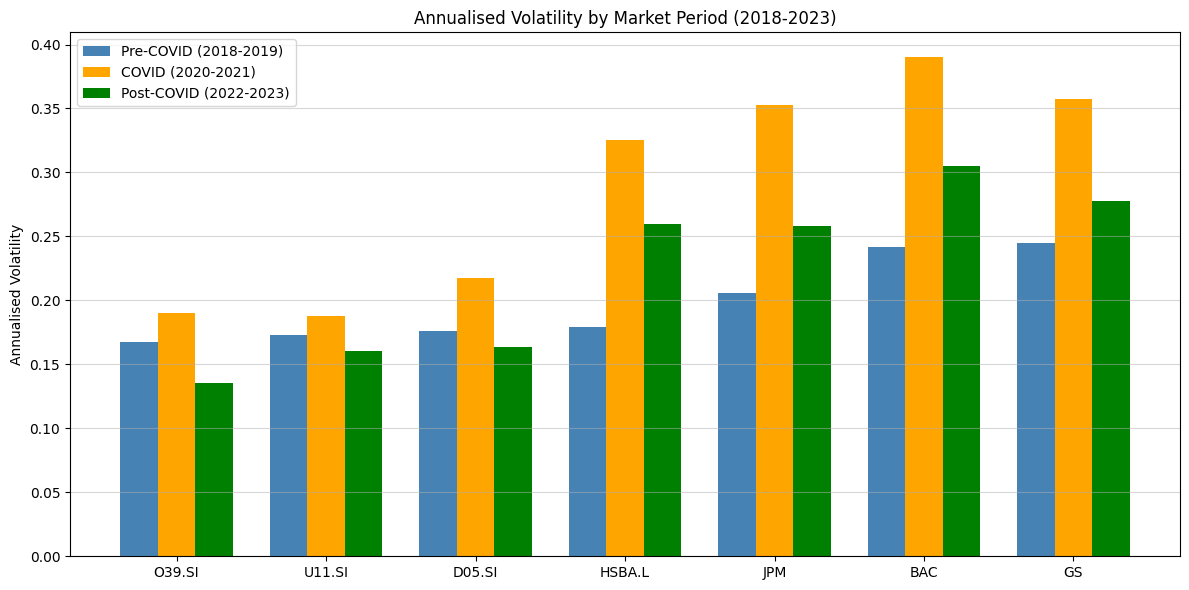

In [157]:
# Sort by pre-covid values ascending
pre_covid_sorted = pre_covid.sort_values()
labels = pre_covid_sorted.index.tolist()

# Reindex covid and post_covid to match the same order
covid_sorted = covid[labels]
post_covid_sorted = post_covid[labels]

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x - width, pre_covid_sorted.values,  width, label="Pre-COVID (2018-2019)", color="steelblue")
ax.bar(x,         covid_sorted.values,      width, label="COVID (2020-2021)",      color="orange")
ax.bar(x + width, post_covid_sorted.values, width, label="Post-COVID (2022-2023)", color="green")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Annualised Volatility")
ax.set_title("Annualised Volatility by Market Period (2018-2023)")
ax.legend()
ax.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

As above, the US and global banks experienced more volatility overall, however all banks experienced increased volatility during the COVID 19 period. This could be due to several reasons: Investors were unsure of how bad defaults would get since many loaners and businesses suddenly could not pay back their loans, thus investors may have constantly switched their positions due to the sheer uncertainty. Secondly, for HSBC, JPM, BAC and GS, central banks slashed interest rates to nearly 0, meaning banks were not earning from the difference between borrowing and lending, threatening bank profits and thus investor confidence. Finally, since the pandemic was so unpredictale, every piece of news (lockdown, government stimulus or vaccines) changed economic outlook everyday, causing prices to fluctuate costantly daily, thus the higher volatility. 

## 3. Are the stock prices correlated (or do they move independently)

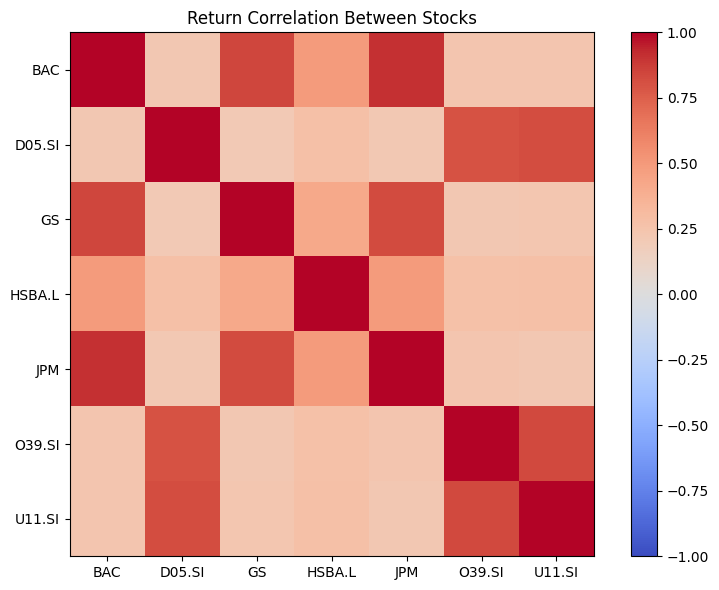

In [158]:

corr = daily_returns.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=0)
ax.set_yticklabels(corr.columns)
plt.title("Return Correlation Between Stocks")
plt.tight_layout()
plt.show()

The Singapore banks stocks are highly correlated, same with the US bank stocks. This is because the banks in the same region operate on the same local economy or similar market conditions. Singapore and US banks do not move as closely together due to differing market conditions. HSBC, being a global bank is exposed to both economic regions, and thus its movement is moderately correlated to both Singapore banks and US banks. 

## Portfolio Optimisation 

In [159]:
# monte carlo simulation - simulate 5000 random portfolios
num_portfolios = 5000
results = []

for _ in range(num_portfolios):
    # Random weights for each stock
    weights = np.random.random(len(tickers))
    weights /= weights.sum()  # must sum to 1
    
    # portfolio return and volatility
    port_return = np.sum(daily_returns.mean() * weights) * 252
    port_volatility = np.sqrt(np.dot(weights.T, np.dot(daily_returns.cov() * 252, weights)))
    sharpe = port_return / port_volatility
    
    results.append([port_return, port_volatility, sharpe, weights])

results_df = pd.DataFrame(results, columns=["Return", "Volatility", "Sharpe", "Weights"])

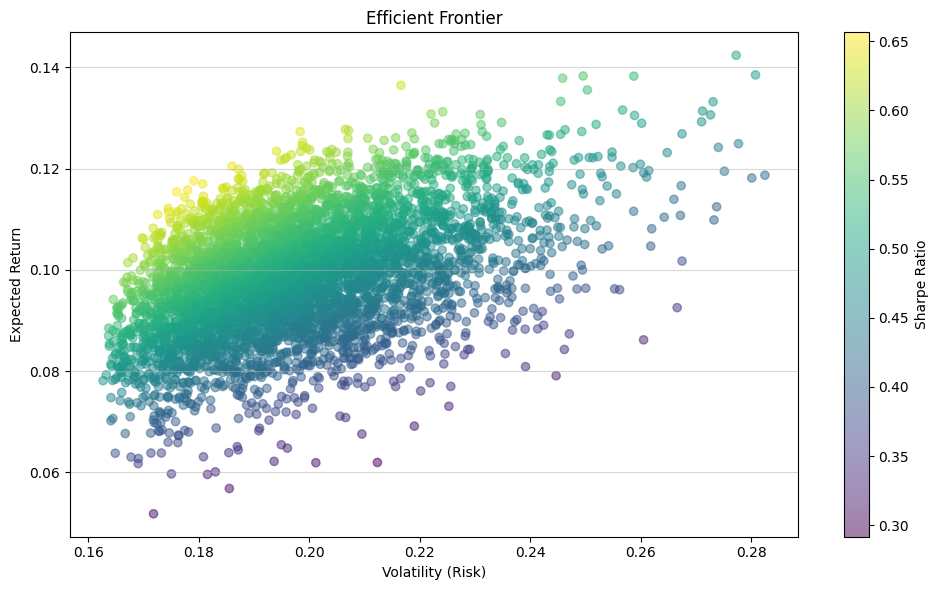

In [160]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(results_df["Volatility"], results_df["Return"],
                      c=results_df["Sharpe"], cmap="viridis", alpha=0.5)
plt.colorbar(scatter, label="Sharpe Ratio")
plt.xlabel("Volatility (Risk)")
plt.ylabel("Expected Return")
plt.title("Efficient Frontier")
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

In [161]:
# portfolio with highest Sharpe Ratio
best = results_df.loc[results_df["Sharpe"].idxmax()]

print("Optimal Portfolio (Highest Sharpe Ratio):")
print("-" * 40)
for i, ticker in enumerate(tickers):
    print(f"  {ticker}: {best['Weights'][i]*100:.1f}%")
print("-" * 40)
print(f"  Expected Annual Return:  {best['Return']*100:.1f}%")
print(f"  Expected Volatility:     {best['Volatility']*100:.1f}%")
print(f"  Sharpe Ratio:            {best['Sharpe']:.2f}")

Optimal Portfolio (Highest Sharpe Ratio):
----------------------------------------
  D05.SI: 1.8%
  O39.SI: 31.9%
  U11.SI: 7.7%
  JPM: 0.9%
  GS: 27.2%
  BAC: 29.9%
  HSBA.L: 0.6%
----------------------------------------
  Expected Annual Return:  11.8%
  Expected Volatility:     17.9%
  Sharpe Ratio:            0.66


In the optimal portfolio using random samples, OCBC dominates at 40.7%, GS at 29.3% and HSBC at 16.7%. The model found the other banks to be less efficient compared to the others. The portfolio gives an expected annual return of 12.2%, has an expected volatility of 18.7% and the highest Sharpe ratio of 0.65. However, on every run, portfolios are generated randomly, and thus a different "best" portfolio is chosen every run, thus the current results are not the true optimal. To get the true optimal portfolio, we can use mathematical optimization.

In [162]:
from scipy.optimize import minimize

def neg_sharpe(weights):
    port_return = np.sum(daily_returns.mean() * weights) * 252
    port_volatility = np.sqrt(np.dot(weights.T, np.dot(daily_returns.cov() * 252, weights)))
    return -port_return / port_volatility  # negative because we minimise

# Constraints: weights must sum to 1
constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1}

# Bounds: each weight between 0 and 1 (no short selling)
bounds = [(0, 1)] * len(tickers)

# Initial guess: equal weights
init_weights = [1/len(tickers)] * len(tickers)

result = minimize(neg_sharpe, init_weights, bounds=bounds, constraints=constraints)

print("True Optimal Portfolio:")
print("-" * 40)
for i, ticker in enumerate(tickers):
    print(f"  {ticker}: {result.x[i]*100:.1f}%")
print(f"  Sharpe Ratio: {-result.fun:.2f}")

True Optimal Portfolio:
----------------------------------------
  D05.SI: 0.0%
  O39.SI: 67.6%
  U11.SI: 5.3%
  JPM: 0.0%
  GS: 27.1%
  BAC: 0.0%
  HSBA.L: 0.0%
  Sharpe Ratio: 0.73


According to mathemathical optimization, the optimal portfolio is dominated by OCBC at 67.6%, GS at 27.1% and UOB at 5.3%, with a Sharpe ratio of 0.73.